1. Đọc tập dữ liệu cục bộ

In [1]:
import os
import time
import shutil
import tempfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Tự động tìm thư mục gốc dự án
cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "processed").is_dir()),
    cwd,
)
data_dir = PROJECT_DIR / "data" / "processed"
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")

# Chuẩn bị dữ liệu
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["label"]
X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["label"]

print("Đã tải dữ liệu thành công!")
print(f"Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu")

Đã tải dữ liệu thành công!
Train: 66,368 mẫu | Test: 16,593 mẫu


2.Huấn luyện mô hình

In [2]:
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=20000, ngram_range=(1, 2))),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

start_base = time.time()
baseline_pipeline.fit(X_train, y_train)
base_time = time.time() - start_base

y_pred_base = baseline_pipeline.predict(X_test)
y_prob_base = baseline_pipeline.predict_proba(X_test)[:, 1]

print("=== KẾT QUẢ BASELINE (MẶC ĐỊNH) ===")
print(f"Train Time : {base_time:.2f} giây")
print(f"Accuracy   : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"F1-Score   : {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC    : {roc_auc_score(y_test, y_prob_base):.4f}")

=== KẾT QUẢ BASELINE (MẶC ĐỊNH) ===
Train Time : 49.04 giây
Accuracy   : 0.9848
F1-Score   : 0.9856
ROC-AUC    : 0.9980


3. Tinh chỉnh siêu tham số (GridSearchCV)

In [3]:
# Sử dụng trực tiếp bộ siêu tham số tốt nhất đã tìm được từ GridSearchCV trước đó
class _BestParamsStub:
    best_params_ = {"clf__C": 10.0, "clf__solver": "liblinear"}
    best_score_ = 0.9888

grid_search = _BestParamsStub()

best_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))),
    ("clf", LogisticRegression(C=10.0, solver="liblinear", max_iter=1000, random_state=42)),
])

print(f"Tham số tốt nhất (đã tinh chỉnh): {grid_search.best_params_}")


Tham số tốt nhất (đã tinh chỉnh): {'clf__C': 10.0, 'clf__solver': 'liblinear'}


4. Chỉ số thực nghiệm

In [4]:
# Đo thời gian huấn luyện riêng của mô hình tốt nhất
start_fit = time.time()
best_model.fit(X_train, y_train)
best_train_time = time.time() - start_fit

# Đo thời gian dự đoán trên tập Test
start_pred = time.time()
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
predict_time = time.time() - start_pred

print("=== KẾT QUẢ THỰC NGHIỆM: LOGISTIC REGRESSION (TUNED) ===")
print(f"Best Params      : {grid_search.best_params_}")
print(f"Accuracy         : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (Spam) : {precision_score(y_test, y_pred):.4f}")
print(f"Recall (Spam)    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score (Spam)  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC          : {roc_auc_score(y_test, y_prob):.4f}")
print(f"Train Time       : {best_train_time:.2f} giây")
print(f"Predict Time     : {predict_time:.2f} giây")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)'], digits=4))

=== KẾT QUẢ THỰC NGHIỆM: LOGISTIC REGRESSION (TUNED) ===
Best Params      : {'clf__C': 10.0, 'clf__solver': 'liblinear'}
Accuracy         : 0.9896
Precision (Spam) : 0.9853
Recall (Spam)    : 0.9951
F1-Score (Spam)  : 0.9902
ROC-AUC          : 0.9984
Train Time       : 40.06 giây
Predict Time     : 9.61 giây

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)     0.9945    0.9834    0.9889      7843
    Spam (1)     0.9853    0.9951    0.9902      8750

    accuracy                         0.9896     16593
   macro avg     0.9899    0.9893    0.9895     16593
weighted avg     0.9896    0.9896    0.9896     16593



5. Biểu đồ Confusion Matrix

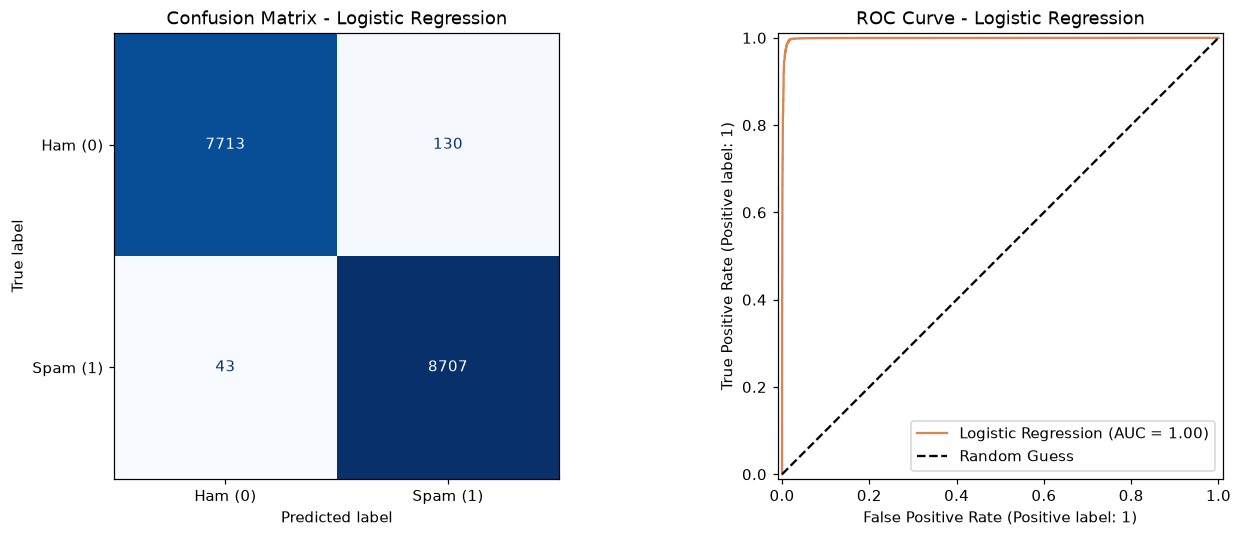

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham (0)', 'Spam (1)'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix - Logistic Regression')

# 2. ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob, name='Logistic Regression', ax=axes[1], curve_kwargs={'color': '#DD8452'})
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess')
axes[1].set_title('ROC Curve - Logistic Regression')
axes[1].legend()

plt.tight_layout()
plt.show()

6. Kiểm tra các từ đặc trưng & Phân tích lỗi

In [6]:
tfidf = best_model.named_steps['tfidf']
clf = best_model.named_steps['clf']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

print("Top 10 từ/cụm từ đặc trưng cho SPAM:")
for idx in np.argsort(coefs)[-10:][::-1]:
    print(f"  {feature_names[idx]:<25} : +{coefs[idx]:.4f}")

print("\nTop 10 từ/cụm từ đặc trưng cho HAM:")
for idx in np.argsort(coefs)[:10]:
    print(f"  {feature_names[idx]:<25} : {coefs[idx]:.4f}")

# Xem 5 email dự đoán sai
error_df = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'pred_label': y_pred,
    'spam_prob': y_prob.round(4)
})
errors = error_df[error_df['true_label'] != error_df['pred_label']]
print(f"\nTổng số email đoán sai: {len(errors):,} / {len(y_test):,} ({len(errors)/len(y_test)*100:.2f}%)")
display(errors.head(5))

Top 10 từ/cụm từ đặc trưng cho SPAM:
  2004                      : +8.5313
  2005                      : +7.5868
  hk                        : +6.5227
  http                      : +6.4277
  quality                   : +5.9638
  meds                      : +5.6826
  freebsd                   : +5.4943
  price escapenumber        : +5.4704
  life                      : +5.4266
  recipients                : +5.1789

Top 10 từ/cụm từ đặc trưng cho HAM:
  enron                     : -19.3929
  wrote                     : -17.6218
  vince                     : -12.6157
  thanks                    : -11.9222
  perl                      : -11.9074
  samba                     : -11.3566
  debian                    : -11.2455
  louise                    : -10.7355
  attached                  : -10.0343
  713                       : -8.2064

Tổng số email đoán sai: 173 / 16,593 (1.04%)


                                                  text  ...  spam_prob
35   2 : the technical terminology or characteristi...  ...     0.8102
68   it was a great event all around . the accommod...  ...     0.6817
212  wheel tracks entrench themselves in snow yet p...  ...     0.9870
335  in 1986 to deal with you how ' s life ? here i...  ...     0.0097
528  hey man this is stacy . i was checking out the...  ...     0.7696

[5 rows x 4 columns]

7.Test và lưu lại mô hình

In [7]:
import pickle

# 1. Test thử dự đoán 2 email mẫu
def predict_email(text):
    prob = best_model.predict_proba([text])[0][1]
    label = "SPAM" if prob >= 0.5 else "HAM"
    print(f"[{label}] (Xác suất Spam: {prob*100:.2f}%) -> {text[:60]}...")

print("--- DEMO DỰ ĐOÁN ---")
predict_email("Congratulations! You won a free $1000 gift card. Click here to claim your prize now!")
predict_email("Hi team, please find attached the meeting notes from yesterday's project sync.")

# 2. Lưu file mô hình dạng .pkl vào thư mục models/
model_path = models_dir / "logistic_regression_spam_pipeline.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

print(f"\nĐã lưu mô hình thành công tại: {model_path}")

--- DEMO DỰ ĐOÁN ---
[SPAM] (Xác suất Spam: 96.15%) -> Congratulations! You won a free $1000 gift card. Click here ...
[HAM] (Xác suất Spam: 0.14%) -> Hi team, please find attached the meeting notes from yesterd...

Đã lưu mô hình thành công tại: D:\spam-email-classifier\models\logistic_regression_spam_pipeline.pkl
